# PROYECTO ATHENA — Hito 5: Simulación Monte Carlo y Análisis de Riesgo

**Grado en Ciencia de Datos Aplicada — UOC**  
Autor: Álvaro Sánchez Mendoza | Tutor: Carlos Gaitán Poyatos

---

## Descripción

Este notebook implementa el motor de simulación estocástica del Proyecto Athena.
Recibe los pesos de la cartera óptima (Hito 4) y genera N escenarios futuros
mediante el método de Monte Carlo, calculando las métricas de riesgo clave:

| Métrica | Descripción |
|---------|-------------|
| **VaR histórico** | Pérdida máxima con nivel de confianza dado |
| **CVaR / Expected Shortfall** | Pérdida media en los peores escenarios |
| **VaR paramétrico** | VaR bajo supuesto de normalidad |
| **Percentiles P10/P50/P90** | Escenarios pesimista/mediano/optimista |
| **Probabilidad de pérdida** | % de escenarios con rentabilidad negativa |

## Estructura del notebook

1. Instalación y verificación de dependencias  
2. Importaciones y configuración  
3. Obtención de datos y cartera óptima (Hitos 3 y 4)  
4. Clase `MonteCarlo` — implementación  
5. Simulación principal — 10.000 escenarios  
6. Visualización — Trayectorias simuladas  
7. Visualización — Distribución de rentabilidades finales  
8. Análisis de sensibilidad (horizonte × confianza)  
9. Resumen y outputs para el Dashboard (Hito 6)  


## 1. Instalación y verificación de dependencias

In [ ]:
import importlib
for pkg, vmin in [('numpy','1.26.0'),('pandas','2.0.0'),
                   ('scipy','1.11.0'),('matplotlib','3.7.0')]:
    try:
        m = importlib.import_module(pkg)
        print(f'  {pkg:<14}: {getattr(m,"__version__","OK"):<12} (mín: {vmin})')
    except ImportError:
        print(f'  {pkg:<14}: NO INSTALADO')


  numpy         : 2.4.4        (mín: 1.26.0)
  pandas        : 3.0.2        (mín: 2.0.0)
  scipy         : 1.17.1       (mín: 1.11.0)
  matplotlib    : 3.10.9       (mín: 3.7.0)


## 2. Importaciones y configuración

In [ ]:
import warnings, logging
from dataclasses import dataclass
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from scipy import stats
import sys
import os
sys.path.append(os.path.abspath("../modules"))
from data_acquisition import DataAcquisition
from optimization import PortfolioOptimizer

warnings.filterwarnings('ignore')
logging.basicConfig(level=logging.INFO,
    format='%(asctime)s [%(levelname)s] %(message)s', datefmt='%H:%M:%S')
logger = logging.getLogger('athena.hito5')

TRADING_DAYS_YEAR = 252
plt.rcParams.update({'figure.figsize':(13,6),'axes.spines.top':False,
    'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.3})
print('Importaciones completadas.')


Importaciones completadas.


## 3. Obtención de datos y cartera óptima

Reutilizamos los módulos de los Hitos 3 y 4 para obtener:
- `returns`: rendimientos históricos limpios
- `msr`: cartera de Máximo Sharpe que usaremos como input de la simulación

In [ ]:
TICKERS = ['SAN.MC','BBVA.MC','TEF.MC','ITX.MC',
           'IBE.MC','REP.MC','ACS.MC','FER.MC']
RISK_FREE_RATE = 0.035
CAPITAL        = 10_000.0   # capital a invertir en euros

# Hito 3 — Adquisición y preprocesado
da = DataAcquisition(tickers=TICKERS, start='2019-01-01',
                     end='2024-12-31', cache_dir=Path('data/cache'))
prices_raw   = da.download(use_cache=True)
prices_clean = da.preprocess(prices_raw)
returns      = da.compute_returns(prices_clean)

# Hito 4 — Cartera óptima (Máximo Sharpe)
opt = PortfolioOptimizer(returns, risk_free_rate=RISK_FREE_RATE,
                         w_min=0.0, w_max=0.40)
msr = opt.max_sharpe()

print(f'Retornos : {returns.shape}')
print(f'MSR Ret  : {msr.expected_return*100:.2f}%  '
      f'Vol: {msr.volatility*100:.2f}%  Sharpe: {msr.sharpe_ratio:.4f}')
print(f'Capital  : {CAPITAL:,.0f} €')


2026-04-24 13:26:45  [INFO]  athena.data_acquisition — DataAcquisition inicializado — 8 activos | 2019-01-01 → 2024-12-31 | frecuencia: 1d | caché: data\cache
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Cargando precios desde caché local: prices_raw_2019-01-01_2024-12-31_1d.csv
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Caché cargada — 1536 días × 8 activos
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Iniciando preprocesado — shape inicial: (1536, 8) | min_valid_ratio=80% | max_consec_nulls=5
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Paso 1 — Todos los activos superan el umbral de calidad (80% datos válidos mínimo).
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Paso 2 — Sin nulos aislados que interpolar.
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Paso 5 — Reindexado a días hábiles: 28 filas añadidas (festivos locales con forward-fill de 1 día).
2026-04-24 13:26:45  [INFO]  athena.data_acquisition — Preprocesado completa

Retornos : (1563, 8)
MSR Ret  : 15.49%  Vol: 19.50%  Sharpe: 0.6147
Capital  : 10,000 €


## 4. Clase `MonteCarlo` — implementación

### Metodología de simulación

Para generar rendimientos futuros correlacionados usamos la **descomposición de Cholesky**:

1. Descomponer $\Sigma = L \cdot L^T$ donde $L$ es la matriz triangular inferior.
2. Generar $Z \sim \mathcal{N}(0, I)$ — normales estándar independientes.
3. Obtener $r = \mu + L \cdot Z$ — normales correlacionadas con la estructura histórica.

El valor acumulado de la cartera en el día $t$:
$$V_t = V_0 \cdot \exp\left(\sum_{s=1}^{t} r_{\text{cartera},s}\right)$$

### Value at Risk (VaR)
$$\text{VaR}_{\alpha} = F^{-1}(\alpha)$$
donde $F^{-1}$ es el cuantil $\alpha$ de la distribución empírica de rentabilidades.

### CVaR / Expected Shortfall
$$\text{CVaR}_{\alpha} = \mathbb{E}[R \mid R \leq \text{VaR}_{\alpha}]$$


In [ ]:
@dataclass
class MonteCarloResult:
    simulations:    np.ndarray
    final_values:   np.ndarray
    final_returns:  np.ndarray
    var_historical: float
    cvar_historical:float
    var_parametric: float
    percentiles:    dict
    prob_loss:      float
    capital:        float
    confidence:     float
    horizon_days:   int
    n_simulations:  int

    def metrics_df(self):
        rows = [
            ('VaR histórico (95%)',         f'{self.var_historical*100:+.2f}%'),
            ('CVaR / ES (95%)',              f'{self.cvar_historical*100:+.2f}%'),
            ('VaR paramétrico (95%)',        f'{self.var_parametric*100:+.2f}%'),
            ('Rentabilidad mediana (P50)',   f'{self.percentiles["P50"]*100:+.2f}%'),
            ('Rentabilidad P10',             f'{self.percentiles["P10"]*100:+.2f}%'),
            ('Rentabilidad P90',             f'{self.percentiles["P90"]*100:+.2f}%'),
            ('Probabilidad de pérdida',      f'{self.prob_loss*100:.1f}%'),
            ('Probabilidad de ganancia',     f'{(1-self.prob_loss)*100:.1f}%'),
            ('Capital inicial',              f'{self.capital:,.0f} €'),
            ('Valor mediano final',          f'{self.capital*(1+self.percentiles["P50"]):,.0f} €'),
            ('Peor escenario (P1)',          f'{self.percentiles["P1"]*100:+.2f}%'),
            ('Mejor escenario (P99)',        f'{self.percentiles["P99"]*100:+.2f}%'),
        ]
        return pd.DataFrame(rows, columns=['Métrica', 'Valor'])


class MonteCarlo:
    """
    Motor de simulación Monte Carlo para carteras de inversión.
    Genera N trayectorias multivariantes usando descomposición de Cholesky.
    Calcula VaR histórico, CVaR y distribución de rentabilidades finales.
    """

    def __init__(self, weights, returns, capital=10_000.0,
                 n_simulations=10_000, horizon_days=252,
                 confidence=0.95, seed=42):

        w = np.asarray(weights, dtype=float)
        if not np.isclose(w.sum(), 1.0, atol=1e-6):
            w /= w.sum()

        self.weights       = w
        self.tickers       = list(returns.columns)
        self.n_assets      = len(self.tickers)
        self.capital       = capital
        self.n_simulations = n_simulations
        self.horizon_days  = horizon_days
        self.confidence    = confidence
        self.seed          = seed

        # Parámetros diarios (escala de simulación)
        self.mu_daily    = returns.mean().values
        self.sigma_daily = returns.cov().values

        logger.info('MonteCarlo: %d sims × %d días | conf=%.0f%% | capital=%.0f€',
                    n_simulations, horizon_days, confidence*100, capital)

    def run(self):
        logger.info('Iniciando simulación...')
        rng = np.random.default_rng(seed=self.seed)

        # Descomposición de Cholesky para conservar correlaciones
        sigma_jitter = self.sigma_daily + np.eye(self.n_assets) * 1e-8
        L = np.linalg.cholesky(sigma_jitter)

        # Generar rendimientos simulados con correlaciones
        # Z: (N_sims, T_días, N_activos) — normales estándar independientes
        Z = rng.standard_normal((self.n_simulations, self.horizon_days, self.n_assets))
        # r = mu + L @ z — transforma a correlacionadas
        returns_sim = self.mu_daily + Z @ L.T

        # Rendimientos diarios de la cartera: r_portfolio = w^T · r
        portfolio_daily = returns_sim @ self.weights

        # Acumular rendimientos: suma acumulada de log-returns
        cum_log = np.cumsum(portfolio_daily, axis=1)

        # Trayectorias de valor: V_t = V_0 · exp(cum_log_t)
        sims = self.capital * np.exp(
            np.hstack([np.zeros((self.n_simulations, 1)), cum_log])
        )

        final_values  = sims[:, -1]
        final_returns = (final_values - self.capital) / self.capital

        # Métricas de riesgo
        alpha    = 1.0 - self.confidence
        var_h    = float(np.percentile(final_returns, alpha * 100))
        cvar_h   = float(np.mean(final_returns[final_returns <= var_h]))
        mu_r, s_r = np.mean(final_returns), np.std(final_returns, ddof=1)
        var_p    = float(mu_r + stats.norm.ppf(alpha) * s_r)

        # Percentiles
        pct = {f'P{p}': float(np.percentile(final_returns, p))
               for p in [1, 5, 10, 25, 50, 75, 90, 95, 99]}

        prob_loss = float(np.mean(final_returns < 0))

        logger.info('Simulación completada — VaR: %.2f%% | CVaR: %.2f%% | P(pérdida): %.1f%%',
                    var_h*100, cvar_h*100, prob_loss*100)

        return MonteCarloResult(
            simulations=sims, final_values=final_values,
            final_returns=final_returns, var_historical=var_h,
            cvar_historical=cvar_h, var_parametric=var_p,
            percentiles=pct, prob_loss=prob_loss,
            capital=self.capital, confidence=self.confidence,
            horizon_days=self.horizon_days, n_simulations=self.n_simulations,
        )


print('Clase MonteCarlo definida correctamente.')


Clase MonteCarlo definida correctamente.


## 5. Simulación principal — 10.000 escenarios

In [ ]:
mc = MonteCarlo(
    weights       = msr.weights.values,
    returns       = returns,
    capital       = CAPITAL,
    n_simulations = 10_000,
    horizon_days  = 252,    # horizonte: 1 año
    confidence    = 0.95,   # nivel de confianza VaR: 95%
    seed          = 42,
)
result = mc.run()

print('Métricas de riesgo:')
print(result.metrics_df().to_string(index=False))


2026-04-24 13:26:45  [INFO]  athena.hito5 — MonteCarlo: 10000 sims × 252 días | conf=95% | capital=10000€
2026-04-24 13:26:45  [INFO]  athena.hito5 — Iniciando simulación...
2026-04-24 13:26:46  [INFO]  athena.hito5 — Simulación completada — VaR: -15.44% | CVaR: -21.98% | P(pérdida): 21.6%


Métricas de riesgo:
                   Métrica    Valor
       VaR histórico (95%)  -15.44%
           CVaR / ES (95%)  -21.98%
     VaR paramétrico (95%)  -19.93%
Rentabilidad mediana (P50)  +16.39%
          Rentabilidad P10   -9.02%
          Rentabilidad P90  +50.42%
   Probabilidad de pérdida    21.6%
  Probabilidad de ganancia    78.4%
           Capital inicial 10,000 €
       Valor mediano final 11,639 €
       Peor escenario (P1)  -26.24%
     Mejor escenario (P99)  +82.77%


## 6. Visualización — Trayectorias simuladas

Representamos una muestra de las 10.000 trayectorias junto con
los percentiles P10, P50 y P90 que delimitan los escenarios
pesimista, mediano y optimista.

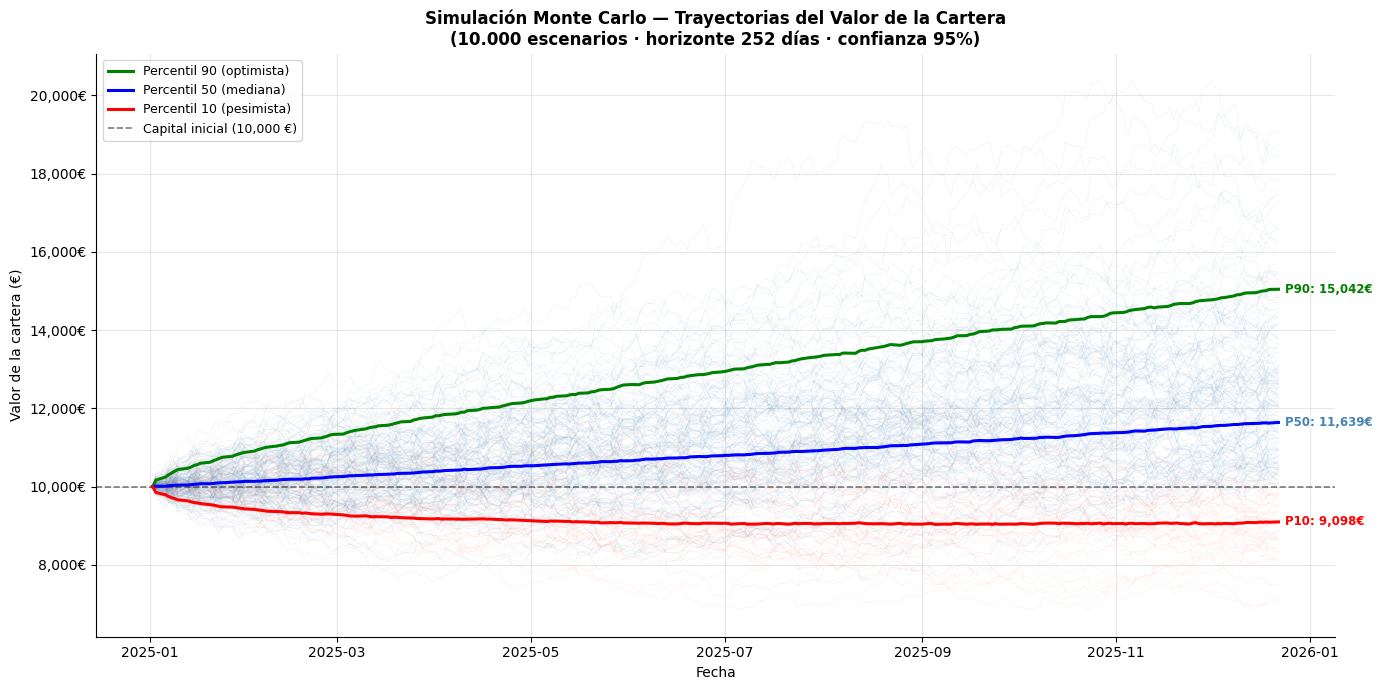

Gráfico guardado: mc_trayectorias.png


In [ ]:
N_SHOW   = 200    # trayectorias a mostrar (para no saturar el gráfico)
DAYS     = np.arange(result.horizon_days + 1)
DATES_MC = pd.bdate_range(start='2025-01-02', periods=result.horizon_days + 1)

# Percentiles de la distribución de trayectorias día a día
p10 = np.percentile(result.simulations, 10, axis=0)
p50 = np.percentile(result.simulations, 50, axis=0)
p90 = np.percentile(result.simulations, 90, axis=0)

fig, ax = plt.subplots(figsize=(14, 7))

# Muestra de trayectorias individuales
rng_plot = np.random.default_rng(0)
idx = rng_plot.choice(result.n_simulations, N_SHOW, replace=False)
for i in idx:
    color = 'tomato' if result.final_values[i] < CAPITAL else 'steelblue'
    ax.plot(DATES_MC, result.simulations[i], color=color,
            alpha=0.08, linewidth=0.6)

# Percentiles destacados
ax.plot(DATES_MC, p90, 'g-',  linewidth=2.2, label='Percentil 90 (optimista)',  zorder=5)
ax.plot(DATES_MC, p50, 'b-',  linewidth=2.2, label='Percentil 50 (mediana)',    zorder=5)
ax.plot(DATES_MC, p10, 'r-',  linewidth=2.2, label='Percentil 10 (pesimista)',  zorder=5)
ax.axhline(CAPITAL, color='black', linestyle='--', linewidth=1.2, alpha=0.5,
           label=f'Capital inicial ({CAPITAL:,.0f} €)', zorder=4)

# Anotaciones finales
for arr, lbl, col in [(p90,'P90','green'),(p50,'P50','steelblue'),(p10,'P10','red')]:
    ax.annotate(f'{lbl}: {arr[-1]:,.0f}€', xy=(DATES_MC[-1], arr[-1]),
                xytext=(5, 0), textcoords='offset points',
                fontsize=8.5, color=col, fontweight='bold', va='center')

ax.set_title(f'Simulación Monte Carlo — Trayectorias del Valor de la Cartera\n'
             f'(10.000 escenarios · horizonte 252 días · confianza 95%)',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Fecha')
ax.set_ylabel('Valor de la cartera (€)')
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f'{x:,.0f}€'))
ax.legend(loc='upper left', fontsize=9)
plt.tight_layout()
plt.savefig('mc_trayectorias.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: mc_trayectorias.png')


## 7. Visualización — Distribución de rentabilidades finales

El histograma de rentabilidades acumuladas al final del horizonte
muestra la distribución completa de resultados posibles.
La línea VaR separa los escenarios de pérdida aceptable del 5%
de peores casos.

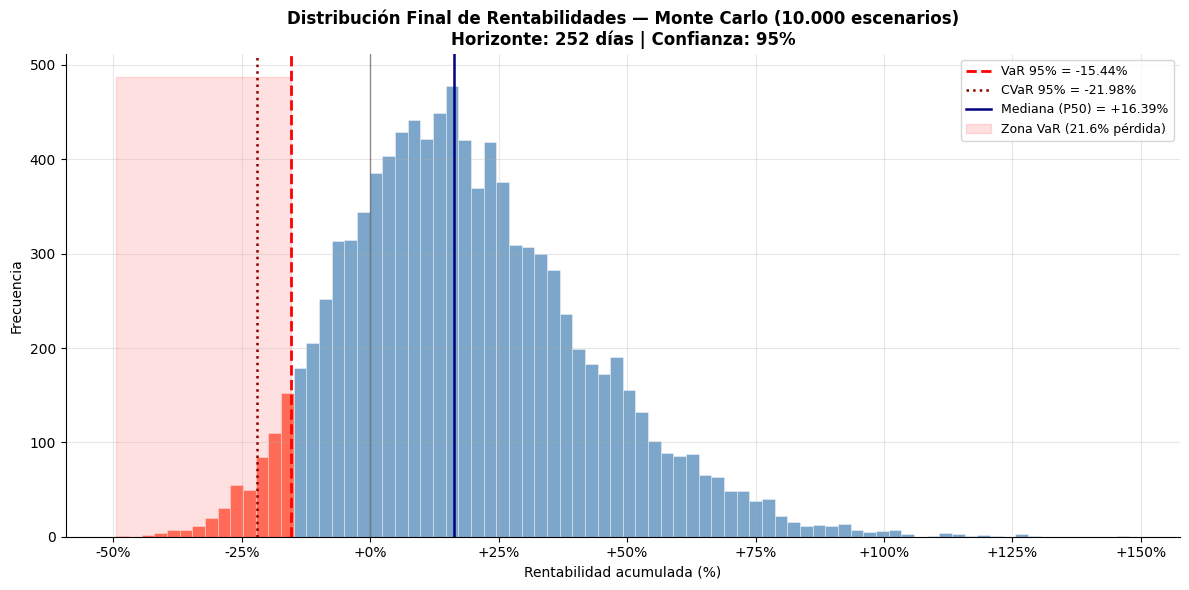

Gráfico guardado: mc_distribucion.png


In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

# Histograma
n, bins, patches = ax.hist(result.final_returns * 100, bins=80,
                            edgecolor='white', linewidth=0.4)

# Colorear barras: rojo si están por debajo del VaR
for patch, left in zip(patches, bins[:-1]):
    if left < result.var_historical * 100:
        patch.set_facecolor('tomato')
        patch.set_alpha(0.85)
    else:
        patch.set_facecolor('steelblue')
        patch.set_alpha(0.70)

# Líneas de referencia
ax.axvline(result.var_historical * 100, color='red', linestyle='--',
           linewidth=2, label=f'VaR 95% = {result.var_historical*100:+.2f}%')
ax.axvline(result.cvar_historical * 100, color='darkred', linestyle=':',
           linewidth=1.8, label=f'CVaR 95% = {result.cvar_historical*100:+.2f}%')
ax.axvline(result.percentiles['P50'] * 100, color='navy', linestyle='-',
           linewidth=1.8, label=f'Mediana (P50) = {result.percentiles["P50"]*100:+.2f}%')
ax.axvline(0, color='black', linestyle='-', linewidth=1, alpha=0.4)

# Anotación zona de pérdida
ax.fill_betweenx([0, n.max()*1.02],
                 bins[0], result.var_historical*100,
                 alpha=0.12, color='red', label=f'Zona VaR ({result.prob_loss*100:.1f}% pérdida)')

ax.set_title('Distribución Final de Rentabilidades — Monte Carlo (10.000 escenarios)\n'
             f'Horizonte: 252 días | Confianza: 95%',
             fontsize=12, fontweight='bold')
ax.set_xlabel('Rentabilidad acumulada (%)')
ax.set_ylabel('Frecuencia')
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter('%+.0f%%'))
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('mc_distribucion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: mc_distribucion.png')


## 8. Análisis de sensibilidad

Evaluamos cómo varía el VaR en función del horizonte temporal
y del nivel de confianza — información clave para el panel
de configuración del dashboard.

In [ ]:
HORIZONS     = [21, 63, 126, 252]    # 1m, 3m, 6m, 1a
CONFIDENCES  = [0.90, 0.95, 0.99]
N_SENS       = 3_000

records = []
for horizon in HORIZONS:
    for conf in CONFIDENCES:
        mc_s = MonteCarlo(msr.weights.values, returns, capital=CAPITAL,
                          n_simulations=N_SENS, horizon_days=horizon,
                          confidence=conf, seed=42)
        r = mc_s.run()
        records.append({
            'Horizonte': f'{horizon}d (~{horizon//21}m)',
            'Confianza (%)': int(conf*100),
            'VaR (%)':  round(r.var_historical*100, 2),
            'CVaR (%)': round(r.cvar_historical*100, 2),
            'P50 (%)':  round(r.percentiles['P50']*100, 2),
            'P(pérdida %)': round(r.prob_loss*100, 1),
        })

df_sens = pd.DataFrame(records)
print('Tabla de sensibilidad del VaR:')
print(df_sens.to_string(index=False))


2026-04-24 13:26:48  [INFO]  athena.hito5 — MonteCarlo: 3000 sims × 21 días | conf=90% | capital=10000€
2026-04-24 13:26:48  [INFO]  athena.hito5 — Iniciando simulación...
2026-04-24 13:26:48  [INFO]  athena.hito5 — Simulación completada — VaR: -5.64% | CVaR: -8.18% | P(pérdida): 41.8%
2026-04-24 13:26:48  [INFO]  athena.hito5 — MonteCarlo: 3000 sims × 21 días | conf=95% | capital=10000€
2026-04-24 13:26:48  [INFO]  athena.hito5 — Iniciando simulación...
2026-04-24 13:26:48  [INFO]  athena.hito5 — Simulación completada — VaR: -7.59% | CVaR: -9.78% | P(pérdida): 41.8%
2026-04-24 13:26:48  [INFO]  athena.hito5 — MonteCarlo: 3000 sims × 21 días | conf=99% | capital=10000€
2026-04-24 13:26:48  [INFO]  athena.hito5 — Iniciando simulación...
2026-04-24 13:26:48  [INFO]  athena.hito5 — Simulación completada — VaR: -11.20% | CVaR: -12.61% | P(pérdida): 41.8%
2026-04-24 13:26:48  [INFO]  athena.hito5 — MonteCarlo: 3000 sims × 63 días | conf=90% | capital=10000€
2026-04-24 13:26:48  [INFO]  athe

Tabla de sensibilidad del VaR:
  Horizonte  Confianza (%)  VaR (%)  CVaR (%)  P50 (%)  P(pérdida %)
  21d (~1m)             90    -5.64     -8.18     1.17          41.8
  21d (~1m)             95    -7.59     -9.78     1.17          41.8
  21d (~1m)             99   -11.20    -12.61     1.17          41.8
  63d (~3m)             90    -7.91    -11.84     4.19          34.3
  63d (~3m)             95   -11.06    -14.17     4.19          34.3
  63d (~3m)             99   -16.16    -18.38     4.19          34.3
 126d (~6m)             90    -9.12    -14.54     8.31          27.4
 126d (~6m)             95   -13.20    -18.04     8.31          27.4
 126d (~6m)             99   -20.63    -24.90     8.31          27.4
252d (~12m)             90    -8.57    -16.97    17.54          20.9
252d (~12m)             95   -15.53    -22.21    17.54          20.9
252d (~12m)             99   -26.16    -32.19    17.54          20.9


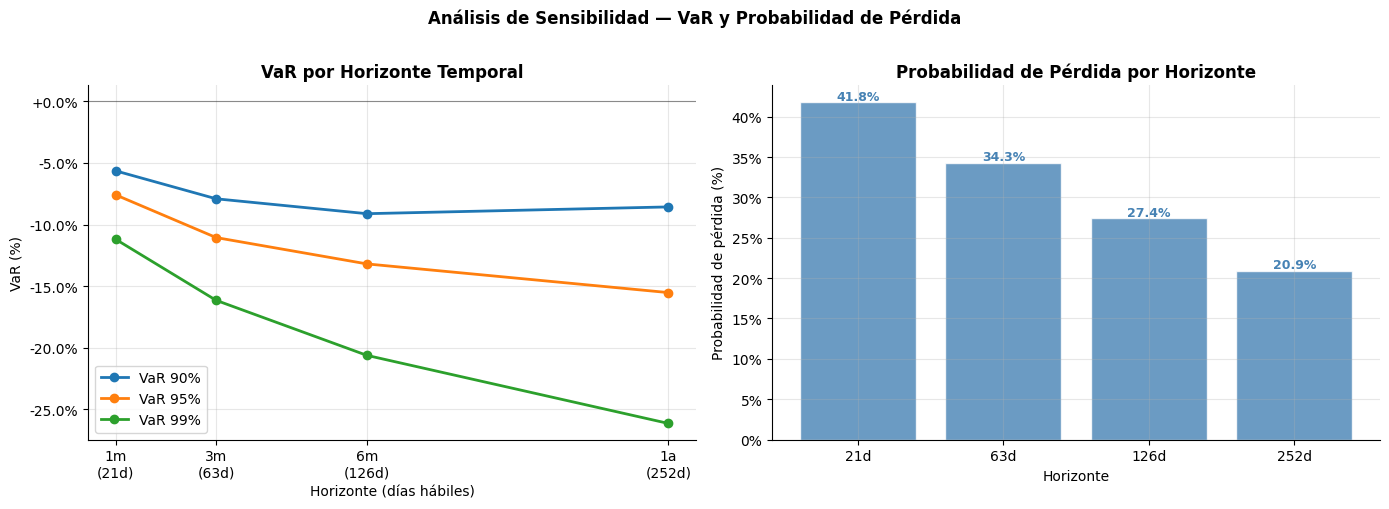

Gráfico guardado: mc_sensibilidad.png


In [ ]:
# Visualización del análisis de sensibilidad
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Izq: VaR por horizonte (una línea por nivel de confianza)
ax1 = axes[0]
for conf in [90, 95, 99]:
    sub = df_sens[df_sens['Confianza (%)']==conf]
    ax1.plot(HORIZONS, sub['VaR (%)'], 'o-', linewidth=2,
             label=f'VaR {conf}%', markersize=6)
ax1.axhline(0, color='black', linewidth=0.8, alpha=0.4)
ax1.set_title('VaR por Horizonte Temporal', fontweight='bold')
ax1.set_xlabel('Horizonte (días hábiles)')
ax1.set_ylabel('VaR (%)')
ax1.set_xticks(HORIZONS)
ax1.set_xticklabels(['1m\n(21d)','3m\n(63d)','6m\n(126d)','1a\n(252d)'])
ax1.yaxis.set_major_formatter(mtick.FormatStrFormatter('%+.1f%%'))
ax1.legend()

# Der: probabilidad de pérdida por horizonte
ax2 = axes[1]
sub95 = df_sens[df_sens['Confianza (%)']==95]
ax2.bar([str(h)+'d' for h in HORIZONS], sub95['P(pérdida %)'],
        color='steelblue', alpha=0.8, edgecolor='white')
for i, (_, row) in enumerate(sub95.iterrows()):
    ax2.text(i, row['P(pérdida %)']+0.3, f"{row['P(pérdida %)']}%",
             ha='center', fontsize=9, fontweight='bold', color='steelblue')
ax2.set_title('Probabilidad de Pérdida por Horizonte', fontweight='bold')
ax2.set_xlabel('Horizonte')
ax2.set_ylabel('Probabilidad de pérdida (%)')
ax2.yaxis.set_major_formatter(mtick.FormatStrFormatter('%.0f%%'))

plt.suptitle('Análisis de Sensibilidad — VaR y Probabilidad de Pérdida',
             fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('mc_sensibilidad.png', dpi=150, bbox_inches='tight')
plt.show()
print('Gráfico guardado: mc_sensibilidad.png')


## 9. Resumen y outputs para el Dashboard (Hito 6)

El Hito 5 produce los siguientes outputs para la Sección 4 del dashboard:

| Variable | Tipo | Descripción |
|----------|------|-------------|
| `result.simulations` | `np.ndarray` (N×T) | Trayectorias completas |
| `result.final_returns` | `np.ndarray` (N,) | Distribución de rentabilidades finales |
| `result.var_historical` | `float` | VaR histórico al 95% |
| `result.cvar_historical` | `float` | CVaR al 95% |
| `result.percentiles` | `dict` | P1–P99 de la distribución |
| `df_sens` | `pd.DataFrame` | Análisis de sensibilidad VaR |


In [ ]:
print('=' * 65)
print('  RESUMEN DEL HITO 5 — Simulación Monte Carlo')
print('=' * 65)
print(f'  Simulaciones     : {result.n_simulations:,}')
print(f'  Horizonte        : {result.horizon_days} días (~1 año)')
print(f'  Capital inicial  : {result.capital:,.0f} €')
print()
print(f'  VaR histórico (95%) : {result.var_historical*100:+.2f}%')
print(f'  CVaR        (95%) : {result.cvar_historical*100:+.2f}%')
print(f'  Mediana P50       : {result.percentiles["P50"]*100:+.2f}%')
print(f'  Prob. pérdida     : {result.prob_loss*100:.1f}%')
print()
import os
for f in ['mc_trayectorias.png','mc_distribucion.png','mc_sensibilidad.png']:
    print(f'  {"✓" if os.path.exists(f) else "✗"} {f}')
print('=' * 65)


  RESUMEN DEL HITO 5 — Simulación Monte Carlo
  Simulaciones     : 10,000
  Horizonte        : 252 días (~1 año)
  Capital inicial  : 10,000 €

  VaR histórico (95%) : -15.44%
  CVaR        (95%) : -21.98%
  Mediana P50       : +16.39%
  Prob. pérdida     : 21.6%

  ✓ mc_trayectorias.png
  ✓ mc_distribucion.png
  ✓ mc_sensibilidad.png
